# RTD-1 / MTD transcriptomics: Specific Objectives 1 and 2

**Objective 1:** collect, evaluate, and prepare available biological datasets.  
**Objective 2:** analyse gene expression, describe cell populations, and identify pathway associations.

This notebook reviews the actual project outputs and recomputes summary tables and plots. Expensive analysis stages can also be rerun using the switches below. **Saved DESeq2 and Scanpy results are loaded by default; displaying them is not a new model fit.**

No multi-omics network integration, target prediction, AI mechanism ranking, or RTD-1 versus MTD comparison is performed. Findings are exploratory and limited by the available data.

**Key distinction:** the 2019 arthritis results are rat; GSE278567 is human THP-1; GSE269120 is rat synovium without peptide treatment. These datasets are analysed separately.

## How to run

Open this notebook from the repository or project directory and use the project Python environment (see [README](README.md) and [requirements](requirements.lock.txt)). Run cells in order.

- `RUN_DOWNLOAD = False`: use the downloaded data already on disk.
- `RUN_ANALYSIS = False`: review existing analyses; set to `True` to rerun preparation, both DESeq2 models, Scanpy, and pathway enrichment. This may take several minutes.
- `RUN_VALIDATION = True`: run the existing source/output consistency checks at the end.

Downloads require internet access. Full reruns require system R with DESeq2 in the project `.Rlib`, plus the Python dependencies. The 396 MB single-cell object is kept locally and excluded from Git. Existing cached inputs and outputs are needed when using review mode.

In [1]:
from pathlib import Path
import os
import sys
import json
import subprocess
import hashlib
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

# Locate the project without relying on one machine's absolute path.
PROJECT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    for root in (candidate, candidate / "rtd1_mtd"):
        if (root / "scripts/prepare.py").exists() and (root / "data/dataset_inventory.tsv").exists():
            PROJECT = root.resolve()
            break
    if PROJECT is not None:
        break
if PROJECT is None:
    raise FileNotFoundError("Open this notebook from the fly-ldsc repository or rtd1_mtd directory.")
REPO = PROJECT.parent
PROCESSED = PROJECT / "data/processed"
RESULTS = PROJECT / "results"
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT / ".cache/matplotlib"))
import matplotlib.pyplot as plt

RUN_DOWNLOAD = False
RUN_ANALYSIS = False
RUN_VALIDATION = True
PYTHON = str(PROJECT / ".venv/bin/python") if (PROJECT / ".venv/bin/python").exists() else sys.executable
# Override this if your configured system R executable is elsewhere.
RSCRIPT = "/usr/bin/Rscript"

pd.set_option("display.max_colwidth", 110)
print("Project:", PROJECT)
print("Notebook Python:", sys.executable)
print("Mode:", "recompute analyses" if RUN_ANALYSIS else "review saved model outputs")

def read_tsv(path, **kwargs):
    return pd.read_csv(path, sep="\t", **kwargs)

def run_stage(command):
    env = os.environ.copy()
    env.update(OPENBLAS_NUM_THREADS="2", OMP_NUM_THREADS="2", NUMBA_NUM_THREADS="2")
    completed = subprocess.run(command, cwd=REPO, env=env, text=True, capture_output=True)
    print(completed.stdout)
    if completed.stderr:
        print(completed.stderr[-6000:])
    completed.check_returncode()

def figure(relative_path, width=1000):
    display(Image(filename=str(RESULTS / relative_path), width=width))

Project: /mnt/hdd_1/rediet/fly-ldsc/rtd1_mtd
Notebook Python: /mnt/hdd_1/rediet/fly-ldsc/rtd1_mtd/.venv/bin/python
Mode: review saved model outputs


## Objective 1 — dataset inventory and availability

The inventory distinguishes expression matrices from processed gene lists and published cytokine/protein figures. A paper or figure is not a sample-level measurement matrix. Public MTD supporting material was collected, but a matched MTD transcriptome was not verified in these resources.

In [2]:
inventory = read_tsv(PROJECT / "data/dataset_inventory.tsv")
display(inventory[["dataset", "species", "assay", "peptide_exposure", "availability"]])
display(inventory[["dataset", "limitations"]])

,dataset,species,assay,peptide_exposure,availability
0,Tongaonkar_2019,Rattus norvegicus,processed bulk RNA-seq differential-expression tables,RTD-1 days 1/3/5 in study; gene lists for days 3/5 in supplement,XLS and supplementary PDF downloaded
1,GSE278567,Homo sapiens,bulk RNA-seq estimated gene counts,RTD-1 0/1/3/10 ug/ml for 20h with/without LPS,count matrix and sample SOFT downloaded
2,GSE269120,Rattus norvegicus,single-cell RNA-seq filtered H5 matrices,no RTD-1 or MTD treatment,two H5 matrices and sample SOFT downloaded
3,Tongaonkar_2019_cytokines,Homo sapiens,cytokine protein secretion assays,RTD-1,article and supplementary figure PDF downloaded
4,Schaal_2017,Rattus norvegicus,cytokines and protease inhibition assays,RTD-1,full article downloaded; supporting items inspected
5,Schaal_2021_MTD12813,Mus musculus; Homo sapiens,cytokines; phagocytosis; host defense assays,MTD12813,article and supplementary PDF downloaded; underlying datasets available from corresponding author on reaso...


,dataset,limitations
0,Tongaonkar_2019,no sample-level count matrix in downloaded supplement; no DESeq2 rerun; day-1 gene list absent; do not tre...
1,GSE278567,fractional E/M estimated counts rounded explicitly; cell line differs from rat synovium; no MTD exposure
2,GSE269120,one library per condition; no replicate-based condition DE or peptide response claims; not a healthy-versu...
3,Tongaonkar_2019_cytokines,figure-level observations; no verified machine-readable sample-level protein matrix in downloaded files
4,Schaal_2017,public supplement lists histology/videos/ARRIVE rather than a sample-level cytokine/proteomics matrix; no ...
5,Schaal_2021_MTD12813,no public matched MTD RNA-seq or direct peptide-interactor matrix verified in this study; mouse infection ...


### Optional download and source integrity

The download script reuses existing files and writes missing downloads atomically. The source manifest records the exact files used in this project snapshot. Reactome `current` URLs can change; preserving matching cached files is necessary for exact reproduction.

In review mode, the checksum cell verifies cached inputs against the existing manifest without changing it. If `RUN_DOWNLOAD=True`, the download script downloads missing files and refreshes that manifest; this records the resulting local snapshot rather than proving it is identical to an older snapshot.

In [3]:
if RUN_DOWNLOAD:
    run_stage([PYTHON, str(PROJECT / "scripts/download.py")])
else:
    print("Using cached inputs; no network download requested.")

manifest = json.loads((PROJECT / "data/source_manifest.json").read_text())
source_checks = []
for item in manifest:
    path = PROJECT / item["file"]
    digest = hashlib.sha256()
    if path.exists():
        with path.open("rb") as stream:
            while chunk := stream.read(1024 * 1024):
                digest.update(chunk)
    source_checks.append({"file": path.name, "bytes": item["bytes"],
                          "exists": path.exists(), "sha256_matches": path.exists() and digest.hexdigest() == item["sha256"]})
source_checks = pd.DataFrame(source_checks)
display(source_checks)
assert source_checks.sha256_matches.all(), "Missing or changed input: inspect the manifest before continuing."

Using cached inputs; no network download requested.


,file,bytes,exists,sha256_matches
0,figshare_8855588.json,5929,True,True
1,PhysiolGen_SupplementaryTables_2019.xls,326656,True,True
2,PhysiolGen_SupplementaryFigures_2019.pdf,549119,True,True
3,paper_2019.html,215044,True,True
4,GSE278567_Partek_THP1_Gene_counts.txt.gz,2287627,True,True
5,GSE278567_family.soft.gz,3494,True,True
6,GSE269120_family.soft.gz,1841,True,True
7,GSE269120_RAW.tar,77824000,True,True
8,Ensembl2Reactome.txt,191313718,True,True
9,reactome_version.txt,2,True,True


### Prepare and validate study-specific inputs

The preparation script reads the original XLS, checks its publisher-provided MD5, preserves reported signed fold changes, maps GEO sample descriptions to matrix columns, and exports sample metadata. It explicitly rounds the fractional Partek E/M estimated bulk counts to the nearest integer for DESeq2; the TMM-normalized file is not used.

In [4]:
if RUN_ANALYSIS:
    run_stage([PYTHON, str(PROJECT / "scripts/prepare.py")])
else:
    print("Loading the previously prepared inputs below.")

rat_tables = {number: read_tsv(PROCESSED / f"rat_2019_S{number}.tsv") for number in (2, 5, 6)}
rat_audit = json.loads((PROCESSED / "rat_2019_audit.json").read_text())
display(pd.DataFrame([{"table": f"S{n}", "rows": len(t),
                       "comparison": t.comparison_as_reported.iloc[0]} for n, t in rat_tables.items()]))
display(pd.Series(rat_audit, name="audit"))

Loading the previously prepared inputs below.


,table,rows,comparison
0,S2,617,PIA vs naive
1,S5,258,RTD-1 vs saline day 3
2,S6,107,RTD-1 vs saline day 5


arthritis_genes_S2                                                                                                                     617
day3_genes_S5                                                                                                                          258
day5_genes_S6                                                                                                                          107
day3_day5_union                                                                                                                        329
day3_day5_overlap                                                                                                                       36
day1_gene_table_available                                                                                                            False
day3_genes_outside_S2                                     [ENSRNOG00000016957, ENSRNOG00000017237, ENSRNOG00000057880, ENSRNOG00000060179]
day5_genes_outside_S2      

### Important discrepancies in the 2019 supplement

S2 has 617 disease-associated genes; S5 and S6 have 258 and 107 entries. Their union is 329 unique IDs, while the paper reports 340 regulated genes across days 1–5. The workbook does not provide a day-1 gene-level table, so these are not identical sets. Four day-3 IDs and one day-5 ID fall outside S2.

Some S5 signed values, including Ccl20 and Mmp9, disagree with the direction described in the narrative. Values are retained verbatim. They are **not log2 fold changes**, and no sign reversal was imposed. The workbook does not supply sample counts or individual adjusted p values for these lists; it cannot support a fresh rat DESeq2 analysis or a rat volcano plot.

In [5]:
selected_symbols = ["Ccl20", "Mmp9", "Scd1", "Il6", "Pparg"]
rat_examples = pd.concat([t[t.symbol.isin(selected_symbols)] for t in rat_tables.values()], ignore_index=True)
display(rat_examples[["source_table", "symbol", "reported_signed_fold_change", "comparison_as_reported"]])

union = set(rat_tables[5].ensembl_id) | set(rat_tables[6].ensembl_id)
assert len(union) == rat_audit["day3_day5_union"] == 329
print("Unique day-3/day-5 IDs:", len(union))

,source_table,symbol,reported_signed_fold_change,comparison_as_reported
0,S2,Scd1,-90.252566,PIA vs naive
1,S2,Pparg,-14.415227,PIA vs naive
2,S2,Mmp9,26.582690,PIA vs naive
3,S2,Il6,36.930160,PIA vs naive
4,S2,Ccl20,73.646144,PIA vs naive
5,S5,Ccl20,3.204403,RTD-1 vs saline day 3
6,S5,Mmp9,2.743962,RTD-1 vs saline day 3
7,S5,Pparg,-1.704284,RTD-1 vs saline day 3
8,S5,Scd1,-1.720932,RTD-1 vs saline day 3
9,S6,Scd1,2.187925,RTD-1 vs saline day 5


Unique day-3/day-5 IDs: 329


### Human bulk study design: GSE278567

24 human THP-1 samples form eight groups: 0, 1, 3, or 10 µg/ml RTD-1, with or without LPS, for 20 h; three samples per group. Sample descriptions establish the exact mapping between GSM accessions and count-column labels. Species and study context are retained.

In [6]:
samples = read_tsv(PROCESSED / "human_samples.tsv")
count_qc = read_tsv(PROCESSED / "human_count_qc.tsv")
display(samples)
display(samples.groupby(["group", "dose_ug_ml", "lps"], observed=True).size().rename("n_samples").reset_index())
display(count_qc)
assert samples["sample"].is_unique and samples.accession.is_unique
assert (samples.groupby("group").size() == 3).all()
assert set(samples.species) == {"Homo sapiens"}

,sample,accession,title,species,dose_ug_ml,lps,group,replicate_label
0,1A,GSM8549051,"THP-1, 20h, vehicle exp1",Homo sapiens,0,False,basal_0,1
1,1C,GSM8549052,"THP-1, 20h, vehicle exp2",Homo sapiens,0,False,basal_0,2
2,1D,GSM8549053,"THP-1, 20h, vehicle exp3",Homo sapiens,0,False,basal_0,3
3,2B,GSM8549054,"THP-1, 20h, 1 µg/ml RTD-1 exp1",Homo sapiens,1,False,basal_1,1
4,2C,GSM8549055,"THP-1, 20h, 1 µg/ml RTD-1 exp2",Homo sapiens,1,False,basal_1,2
5,2D,GSM8549056,"THP-1, 20h, 1 µg/ml RTD-1 exp3",Homo sapiens,1,False,basal_1,3
6,3A,GSM8549057,"THP-1, 20h, 3 µg/ml RTD-1 exp1",Homo sapiens,3,False,basal_3,1
7,3B,GSM8549058,"THP-1, 20h, 3 µg/ml RTD-1 exp2",Homo sapiens,3,False,basal_3,2
8,3D,GSM8549059,"THP-1, 20h, 3 µg/ml RTD-1 exp3",Homo sapiens,3,False,basal_3,3
9,4A,GSM8549060,"THP-1, 20h, 10 µg/ml RTD-1 exp1",Homo sapiens,10,False,basal_10,1


,group,dose_ug_ml,lps,n_samples
0,LPS_0,0,True,3
1,LPS_1,1,True,3
2,LPS_10,10,True,3
3,LPS_3,3,True,3
4,basal_0,0,False,3
5,basal_1,1,False,3
6,basal_10,10,False,3
7,basal_3,3,False,3


,sample,estimated_library_size,rounded_library_size,detected_genes,fraction_entries_noninteger
0,1A,2.521565e+07,25215664,22944,0.363827
1,1C,2.955478e+07,29554831,22993,0.376268
2,1D,2.769839e+07,27698381,22871,0.370523
3,2B,2.342044e+07,23420450,22930,0.361886
4,2C,2.889165e+07,28891688,23042,0.378170
5,2D,2.625933e+07,26259367,22803,0.366284
6,3A,2.485141e+07,24851411,22814,0.356894
7,3B,2.613326e+07,26133279,22698,0.363629
8,3D,2.253091e+07,22530914,22636,0.356101
9,4A,2.555226e+07,25552271,22596,0.360341


Input features: 25,240; retained for DESeq2: 17,790


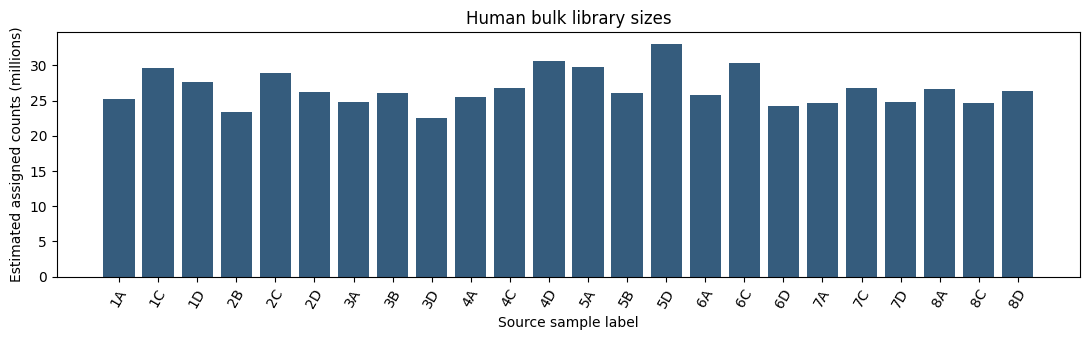

In [7]:
counts = read_tsv(PROCESSED / "human_counts_rounded.tsv", index_col=0)
assert list(counts.columns) == list(samples["sample"])
assert np.isfinite(counts.to_numpy()).all() and (counts.to_numpy() >= 0).all()
assert (counts.to_numpy() == np.floor(counts.to_numpy())).all()
keep = (counts >= 10).sum(axis=1) >= 3
print(f"Input features: {len(counts):,}; retained for DESeq2: {keep.sum():,}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(count_qc["sample"], count_qc.estimated_library_size / 1e6, color="#355c7d")
ax.set(ylabel="Estimated assigned counts (millions)", xlabel="Source sample label", title="Human bulk library sizes")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

### Rat single-cell study design: GSE269120

These samples are **inflamed synovium treated with control or clodronate liposomes**, not healthy controls and not RTD-1/MTD treatment. The public matrices represent one sequenced library per condition. Cell-level observations do not replace biological replication.

In [8]:
sc_samples = read_tsv(PROCESSED / "rat_singlecell_samples.tsv")
display(sc_samples)
assert len(sc_samples) == 2 and set(sc_samples.species) == {"Rattus norvegicus"}

,accession,title,species,characteristics
0,GSM8306635,"Synovium, Control",Rattus norvegicus,tissue: Synovium; genotype: WT; treatment: Control liposome injection
1,GSM8306636,"Synovium, Clodronate",Rattus norvegicus,tissue: Synovium; genotype: WT; treatment: Clodronate liposome injection


## Objective 2 — human differential expression with DESeq2

**Primary model:** `~ group`, with six within-LPS-stratum contrasts (each nonzero RTD-1 dose versus its vehicle). Filtering requires ≥10 counts in ≥3 samples. Significance is BH adjusted p <0.05 within each contrast, with no additional effect-size threshold. Fold changes are unshrunken.

**Sensitivity model:** `~ replicate_label + group`. PCA suggests a shared shift of the third labelled replicate, but the metadata do not verify an experimental block. The adjustment is a sensitivity analysis and does not replace the primary model. Fractional-count rounding, sample size, and unresolved experimental structure limit confirmatory interpretation.

The following cell runs the real R scripts only if `RUN_ANALYSIS=True`; otherwise it loads their saved outputs. Full model code is in [`scripts/bulk_deseq2.R`](scripts/bulk_deseq2.R).

DESeq2 fits are not being rerun; reading existing results.


,contrast,tested,adjusted,significant,up,down
0,basal_1_vs_0,17790,17790,0,0,0
1,basal_3_vs_0,17790,17790,2,2,0
2,basal_10_vs_0,17790,13996,587,414,173
3,LPS_1_vs_0,17790,17790,1,0,1
4,LPS_3_vs_0,17790,17790,5,2,3
5,LPS_10_vs_0,17790,13651,595,280,315


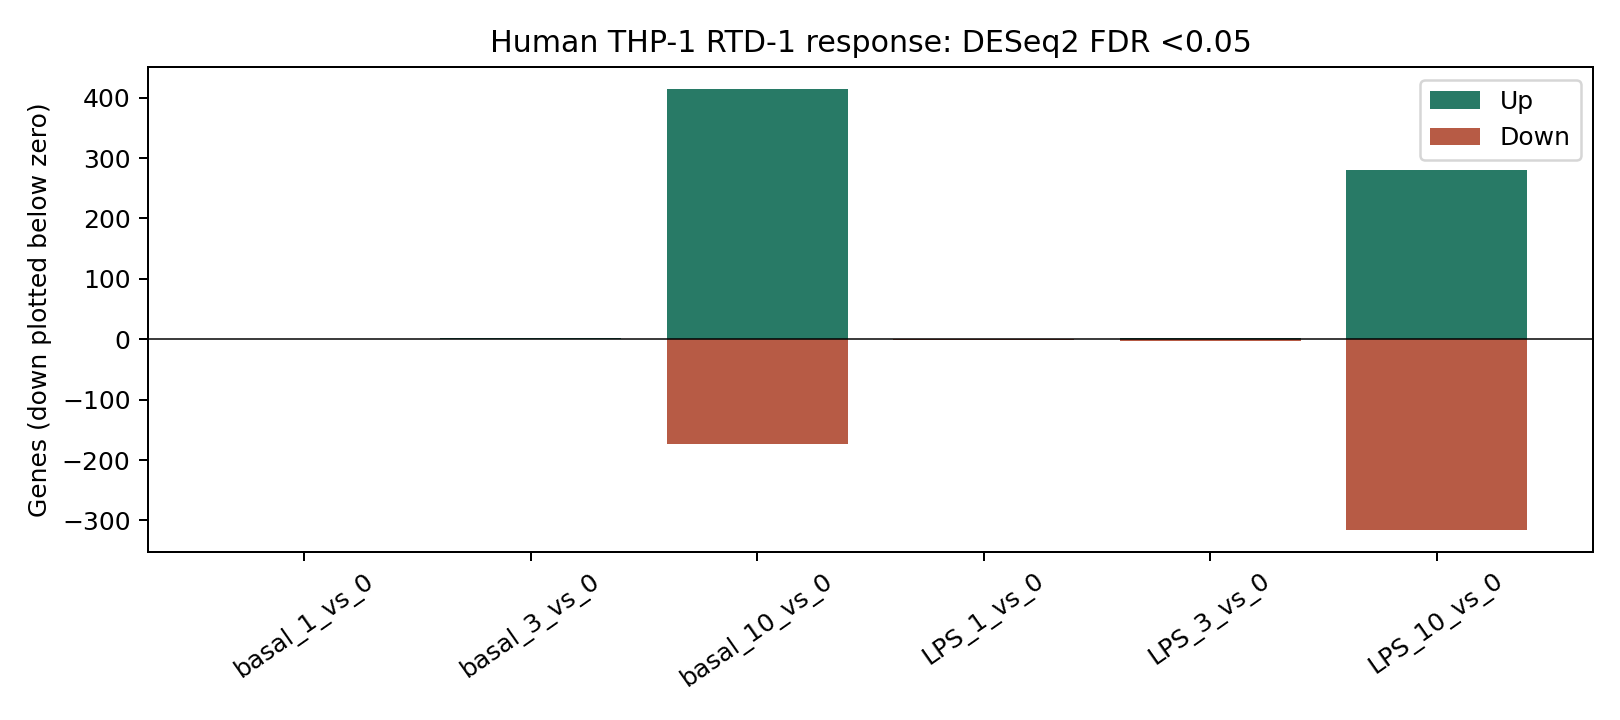

In [9]:
if RUN_ANALYSIS:
    run_stage([RSCRIPT, str(PROJECT / "scripts/bulk_deseq2.R")])
    run_stage([RSCRIPT, str(PROJECT / "scripts/bulk_deseq2.R"), "--block-sensitivity"])
else:
    print("DESeq2 fits are not being rerun; reading existing results.")

bulk_summary = read_tsv(RESULTS / "bulk/contrast_summary.tsv")
display(bulk_summary)
figure("bulk/deg_counts.png")

### Examine a contrast and selected genes

Change `CONTRAST` to any value in the summary. The table below is selected by adjusted p value for inspection; it is not a molecular-target ranking. Differential-expression result rows retain separate source `_PAR_Y` features, whereas pathway analysis collapses them to unique stable gene IDs.

,gene_id,gene_name,baseMean,log2FoldChange,lfcSE,pvalue,padj
0,ENSG00000130589.16,HELZ2,4663.249956,1.323470,0.095278,7.214873e-44,1.009794e-39
1,ENSG00000132530.17,XAF1,2042.927125,1.637332,0.119431,8.912276e-43,6.236811e-39
2,ENSG00000160932.11,LY6E,5285.588876,1.941096,0.177470,7.621265e-28,3.555574e-24
3,ENSG00000164054.17,SHISA5,4013.049620,1.052365,0.098127,7.807847e-27,2.731966e-23
4,ENSG00000025708.14,TYMP,5048.313092,1.217288,0.122656,3.260077e-23,9.125607e-20
5,ENSG00000172936.16,MYD88,1840.534243,0.567126,0.060364,5.715455e-21,1.333225e-17
6,ENSG00000185507.21,IRF7,1771.208856,1.732790,0.185400,9.084358e-21,1.816353e-17
7,ENSG00000055332.19,EIF2AK2,3874.931662,1.443701,0.158202,7.127353e-20,1.246930e-16
8,ENSG00000100129.18,EIF3L,8246.502367,-0.292145,0.033302,1.745874e-18,2.715028e-15
9,ENSG00000115415.20,STAT1,13713.743259,1.358646,0.155941,2.970659e-18,4.157735e-15


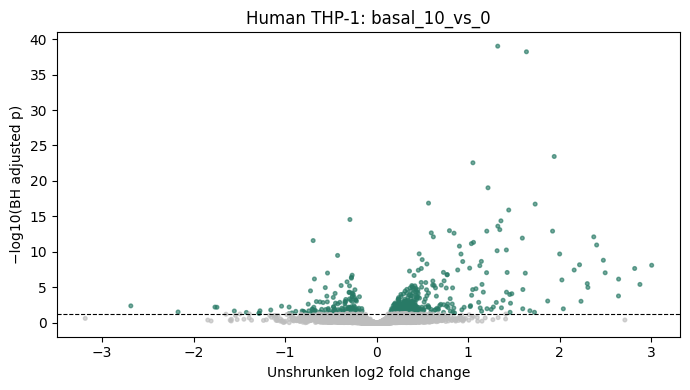

In [10]:
CONTRAST = "basal_10_vs_0"
assert CONTRAST in set(bulk_summary.contrast)
de = read_tsv(RESULTS / f"bulk/{CONTRAST}.tsv")
display(de[["gene_id", "gene_name", "baseMean", "log2FoldChange", "lfcSE", "pvalue", "padj"]].head(20))

plot_data = de.dropna(subset=["log2FoldChange", "padj"])
significant = plot_data.padj < 0.05
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(plot_data.log2FoldChange, -np.log10(plot_data.padj.clip(lower=1e-300)),
           c=np.where(significant, "#287a66", "#bdbdbd"), s=7, alpha=0.65)
ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=0.8)
ax.set(xlabel="Unshrunken log2 fold change", ylabel="−log10(BH adjusted p)",
       title=f"Human THP-1: {CONTRAST}")
plt.tight_layout()
plt.show()

### Sample PCA and model sensitivity

The PCA below uses variance-stabilized expression from the primary R fit. The third labelled replicate shifts systematically on PC2 across treatment groups. Samples were retained; both model results are shown so this uncertainty is explicit. Significant-feature counts can change substantially after candidate-block adjustment.

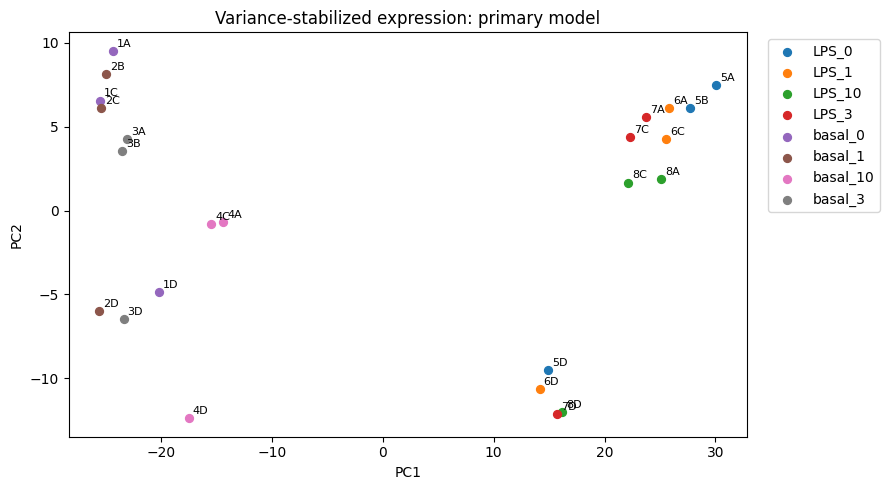

,contrast,primary_significant,candidate_block_significant,shared_significant,shared_same_direction
0,basal_1_vs_0,0,8,0,0
1,basal_3_vs_0,2,40,2,2
2,basal_10_vs_0,587,1411,574,574
3,LPS_1_vs_0,1,5,1,1
4,LPS_3_vs_0,5,44,4,4
5,LPS_10_vs_0,595,1541,594,594


In [11]:
pca = read_tsv(RESULTS / "bulk/sample_qc.tsv")
fig, ax = plt.subplots(figsize=(9, 5))
for label, frame in pca.groupby("group", observed=True):
    ax.scatter(frame.PC1, frame.PC2, label=label, s=32)
    for row in frame.itertuples():
        ax.annotate(row.sample, (row.PC1, row.PC2), xytext=(3, 3), textcoords="offset points", fontsize=8)
ax.set(xlabel="PC1", ylabel="PC2", title="Variance-stabilized expression: primary model")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

sensitivity_summary = read_tsv(RESULTS / "bulk_sensitivity/contrast_summary.tsv")
comparison = []
for row in bulk_summary.itertuples():
    primary = read_tsv(RESULTS / f"bulk/{row.contrast}.tsv").set_index("gene_id")
    blocked = read_tsv(RESULTS / f"bulk_sensitivity/{row.contrast}.tsv").set_index("gene_id").reindex(primary.index)
    shared = (primary.padj < 0.05) & (blocked.padj < 0.05)
    comparison.append({"contrast": row.contrast, "primary_significant": row.significant,
                       "candidate_block_significant": int((blocked.padj < 0.05).sum()),
                       "shared_significant": int(shared.sum()),
                       "shared_same_direction": int((np.sign(primary.loc[shared, "log2FoldChange"]) ==
                                                      np.sign(blocked.loc[shared, "log2FoldChange"])).sum())})
display(pd.DataFrame(comparison))

## Objective 2 — descriptive rat single-cell analysis

The Scanpy workflow performs per-library QC, normalization to 10,000 counts/cell and log1p transformation, selection of 2,000 highly variable genes with sample-aware selection, PCA, an exact 15-neighbor graph on 30 PCs, UMAP, and Leiden clustering (resolution 0.6, seed 0).

QC retains cells with 200–6,000 detected genes, ≤50,000 counts, and <15% mitochondrial counts; genes must occur in ≥3 cells. No condition-removing batch integration was applied. Doublets and ambient RNA were not explicitly corrected. Markers are descriptive cluster statistics; no replicate-based condition differential expression is performed.

The count object and code are available at `data/processed/rat_synovium.h5ad` and [`scripts/singlecell.py`](scripts/singlecell.py).

Scanpy preprocessing/clustering are not being rerun; reading saved outputs.


,sample,input_cells,retained_cells,mitochondrial_features
0,GSM8306635,9006,8751,13
1,GSM8306636,10339,10283,13


species                                                                                                                          Rattus norvegicus
peptide_treated                                                                                                                              False
samples                                                                                                                                          2
qc                                                            200–6000 detected genes; <=50000 UMIs; mitochondrial counts <15%; genes in >=3 cells
normalization                                                                                                         10000 counts per cell, log1p
hvg                                                                                                                                           2000
embedding                                                  40 PCs; exact sklearn 15 neighbors on 30 PCs; UMAP seed 0; 

Retained cells: 19,034


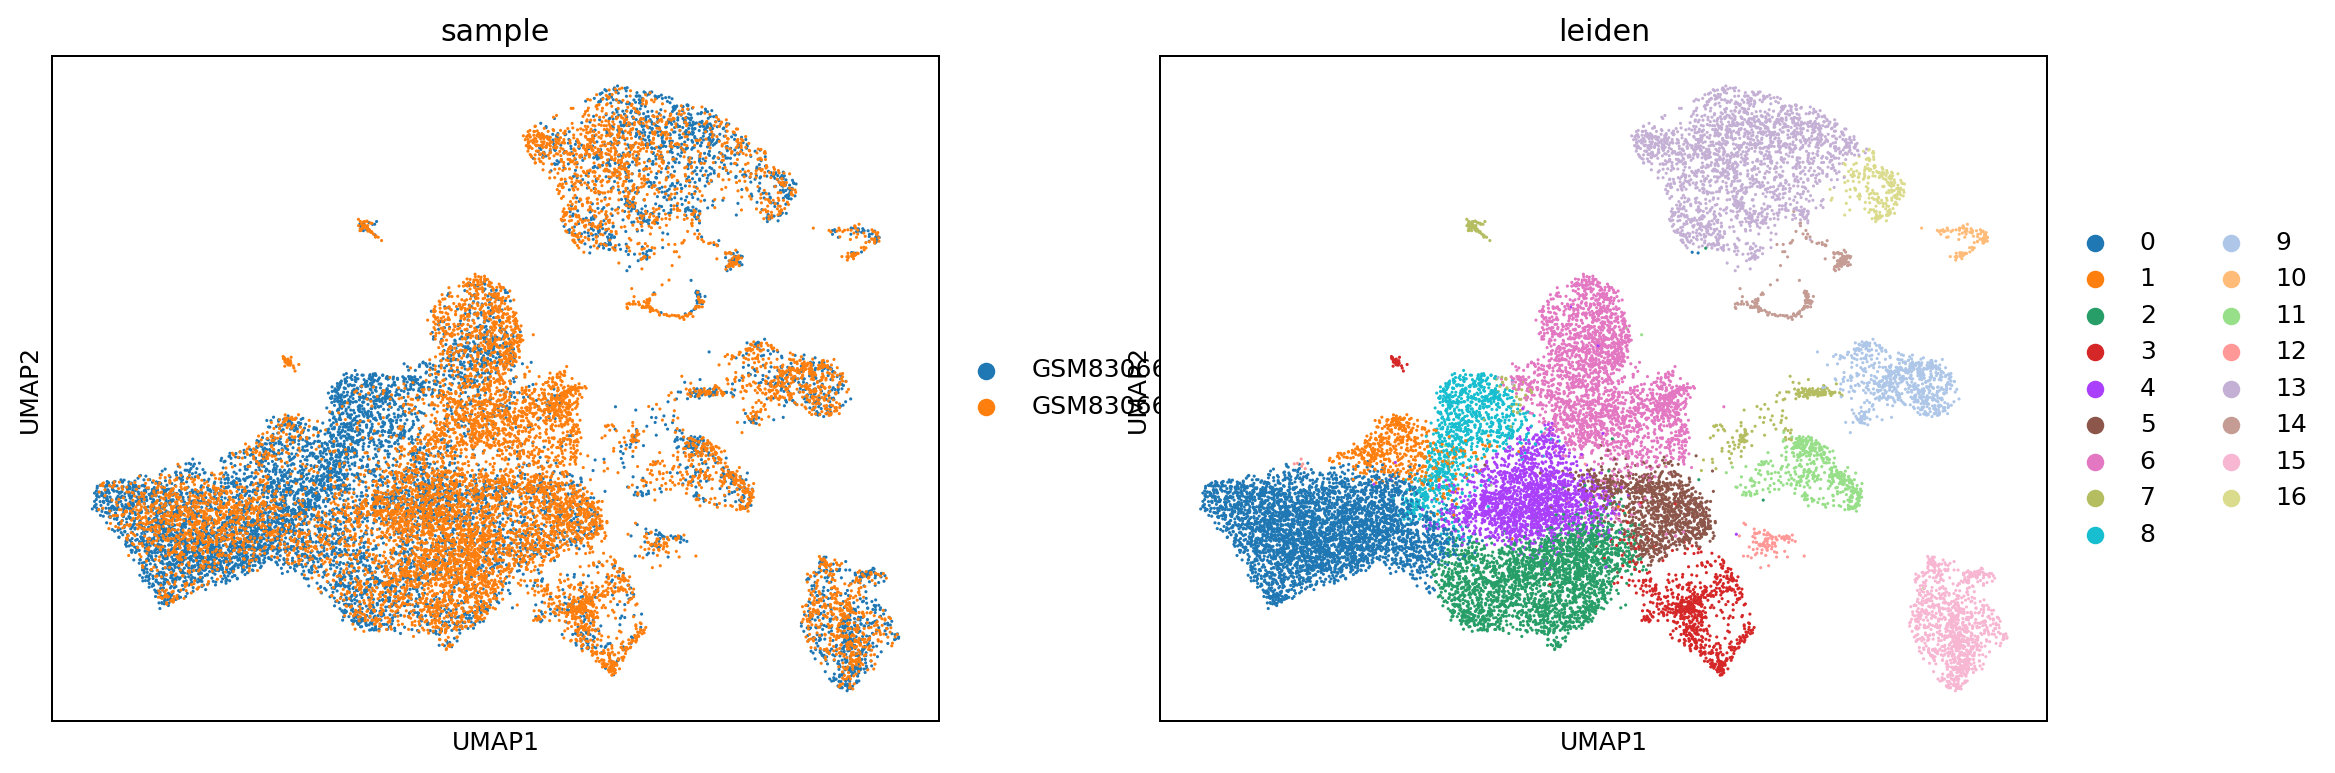

In [12]:
if RUN_ANALYSIS:
    run_stage([PYTHON, str(PROJECT / "scripts/singlecell.py")])
else:
    print("Scanpy preprocessing/clustering are not being rerun; reading saved outputs.")

sc_qc = read_tsv(RESULTS / "singlecell/qc_summary.tsv")
sc_methods = json.loads((RESULTS / "singlecell/methods.json").read_text())
display(sc_qc)
display(pd.Series(sc_methods, name="method"))
print("Retained cells:", f"{sc_qc.retained_cells.sum():,}")
figure("singlecell/umap.png")

### Marker evidence and provisional cell identities

The annotations are broad, marker-supported labels, not validated subtypes. Cluster 7 remains unresolved; cluster 12 has mixed stromal/lymphocyte markers and may reflect doublets or ambient RNA. Clusters 1 and 5 have stress-related signatures. The evidence table is manually curated for this recorded clustering and must be reviewed if clustering changes.

,cluster,provisional_cell_type,marker_evidence,caution
0,0,fibroblast,Col1a1;Dcn;Lum;Pdgfra;Htra3;Igfbp5,broad identity; not a validated subtype
1,1,fibroblast,Col1a1;Dcn;Lum;Mfap5;Dpp4,heat-shock signature Hspa1b/Hspb1; stress may drive clustering
2,2,fibroblast,Col1a1;Dcn;Lum;Pdgfra;Tnfaip6;Tfpi2,broad identity; not a validated subtype
3,3,fibroblast,Col1a1;Dcn;Fmod;Thbs4;Tnmd,stromal/tendon-associated markers; subtype unresolved
4,4,fibroblast,Col1a1;Dcn;Lum;Pdgfra;Prg4;Ccn3,broad identity; not a validated subtype
5,5,fibroblast,Col1a1;Dcn;Lum;Pdgfra,heat-shock/immediate-early signature Hspa1b/Fos; stress may drive clustering
6,6,fibroblast,Col1a1;Dcn;Lum;Pdgfra;Fn1;Tnn;Mmp3,broad identity; not a validated subtype
7,7,unresolved,Cfl1;Tmsb4x;Myl12a;Actb;Rpl35,low-specificity markers; do not assign a cell type
8,8,fibroblast,Col1a1;Col3a1;Dcn;Lum;Pdgfra;Cthrc1,broad identity; not a validated subtype
9,9,endothelial,Pecam1;Cdh5;Kdr;Emcn;Vwf;Flt1,provisional marker-based annotation


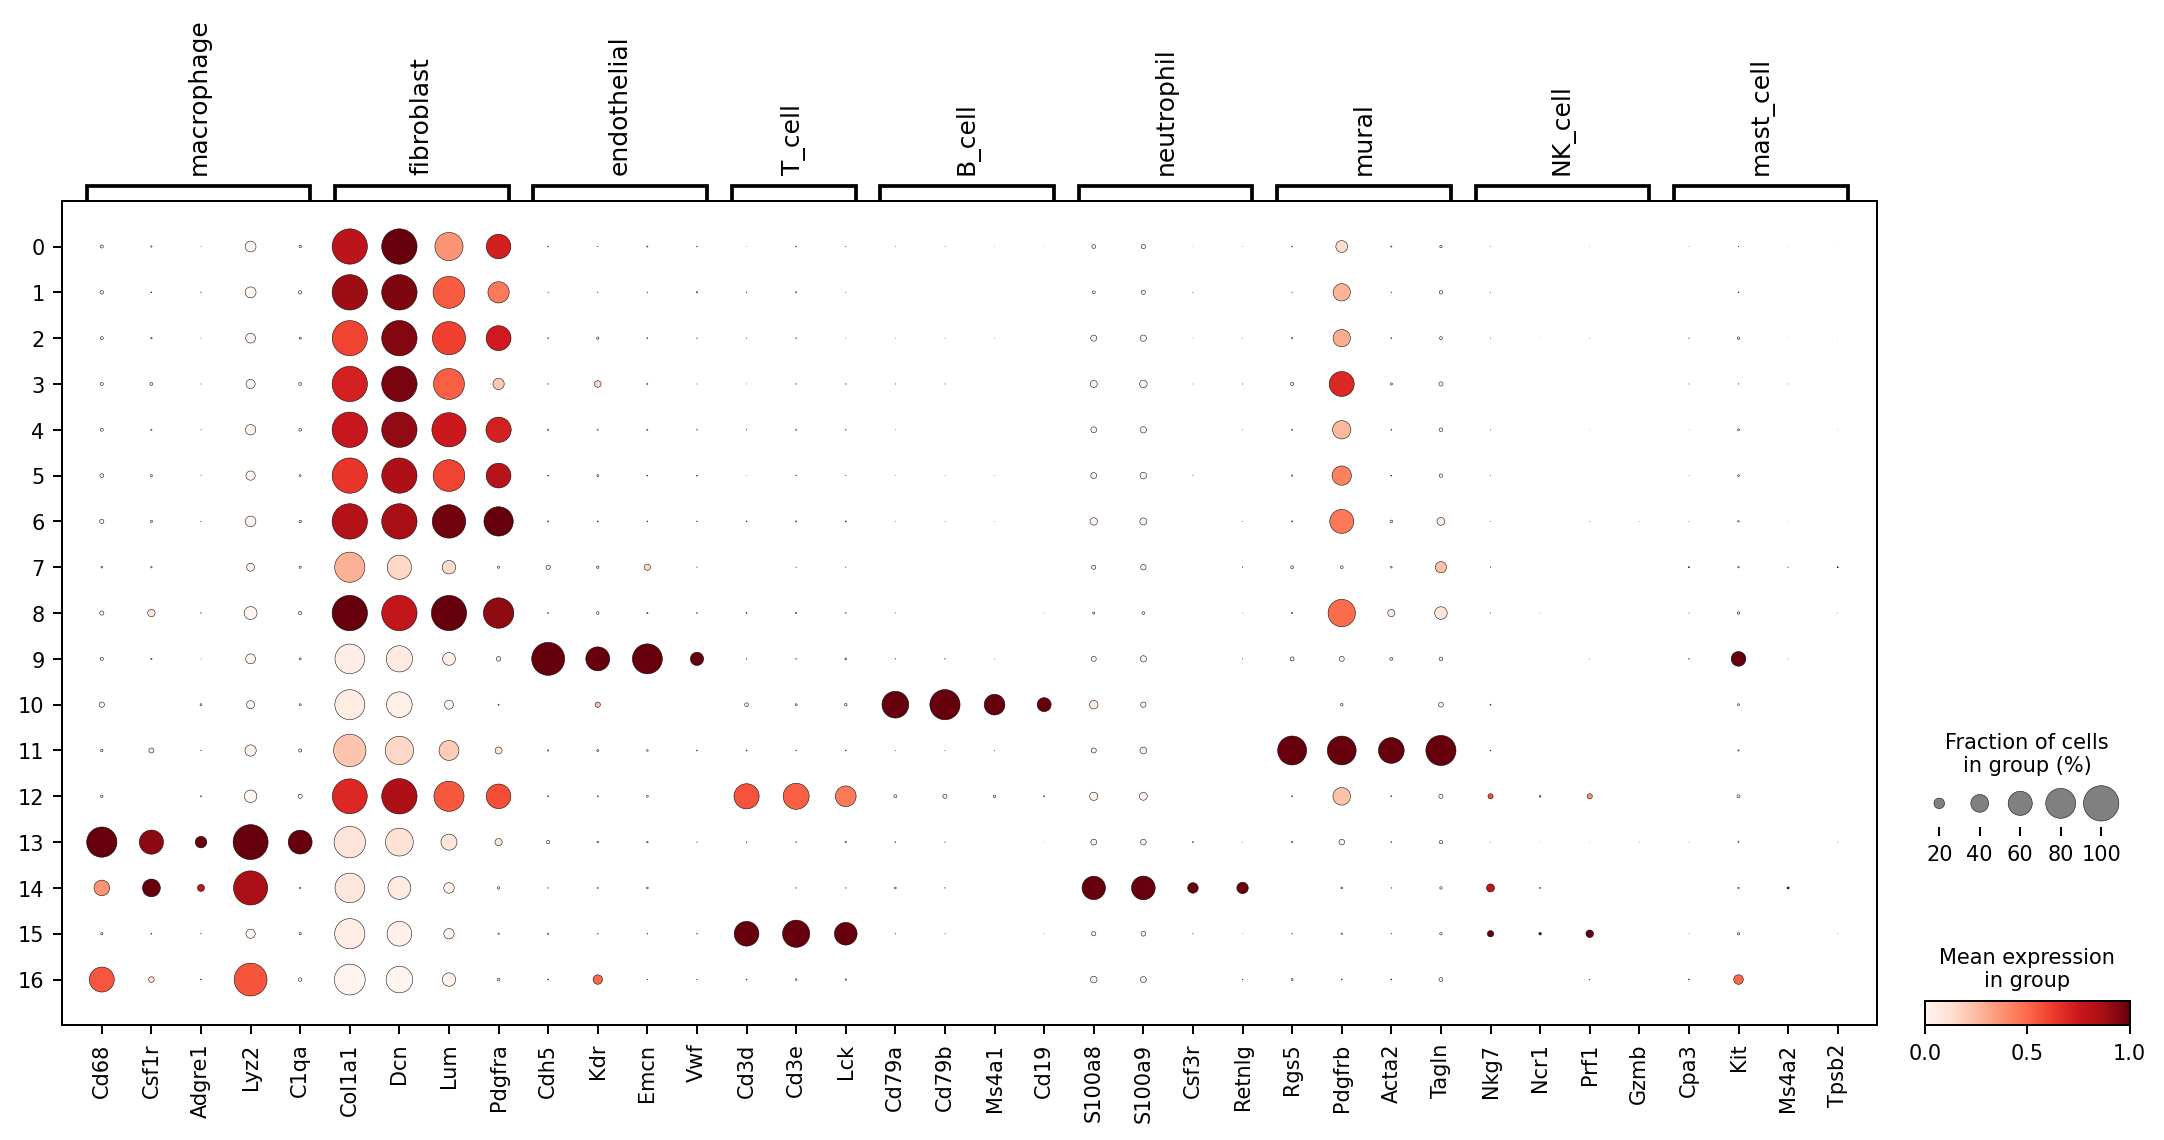

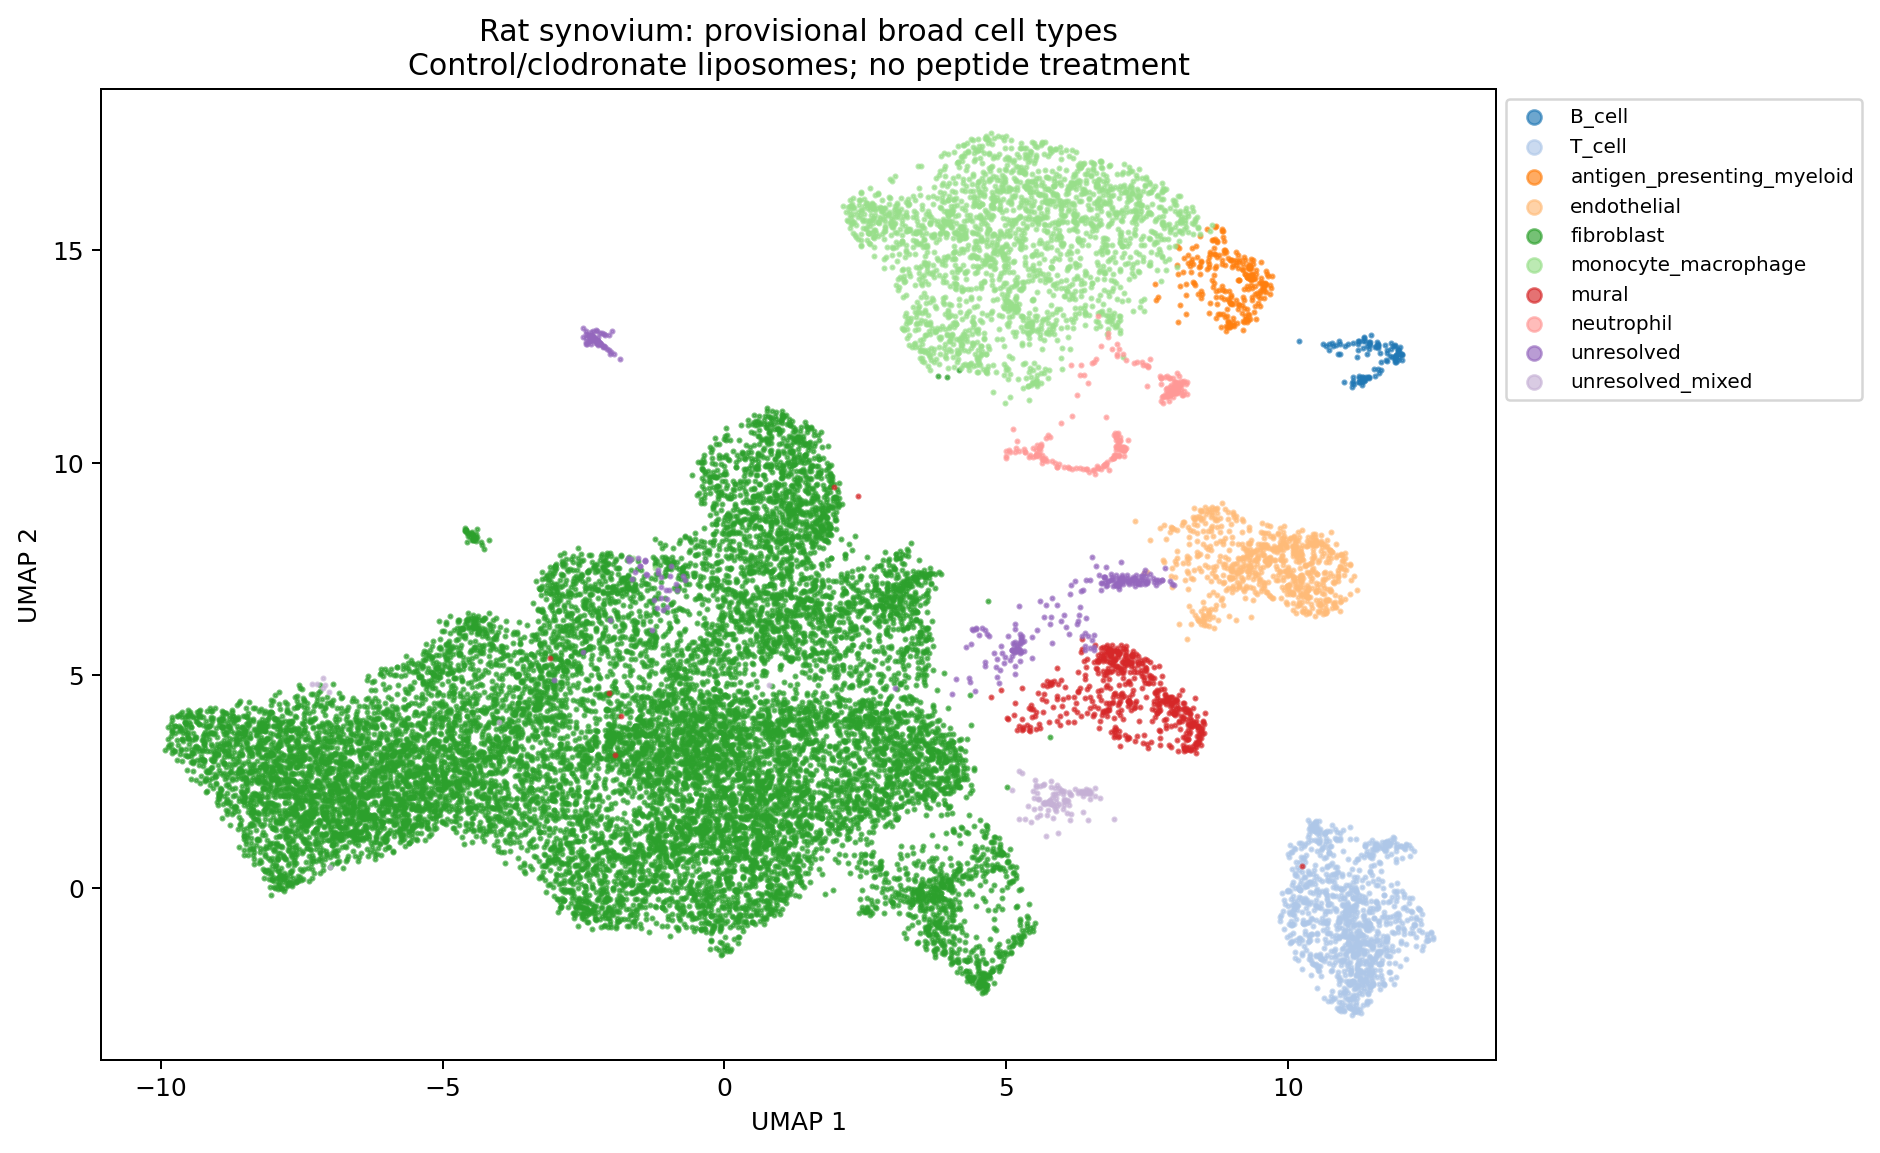

In [13]:
annotations = read_tsv(PROJECT / "data/cluster_annotation.tsv", dtype={"cluster": str})
display(annotations)
figure("singlecell/marker_dotplot.png", width=1200)
figure("singlecell/umap_celltypes.png", width=1100)

sample,GSM8306635,GSM8306636
provisional_cell_type,,
B_cell,39,61
T_cell,501,474
antigen_presenting_myeloid,119,115
endothelial,233,447
fibroblast,6493,7392
monocyte_macrophage,929,1131
mural,182,302
neutrophil,67,150
unresolved,139,156


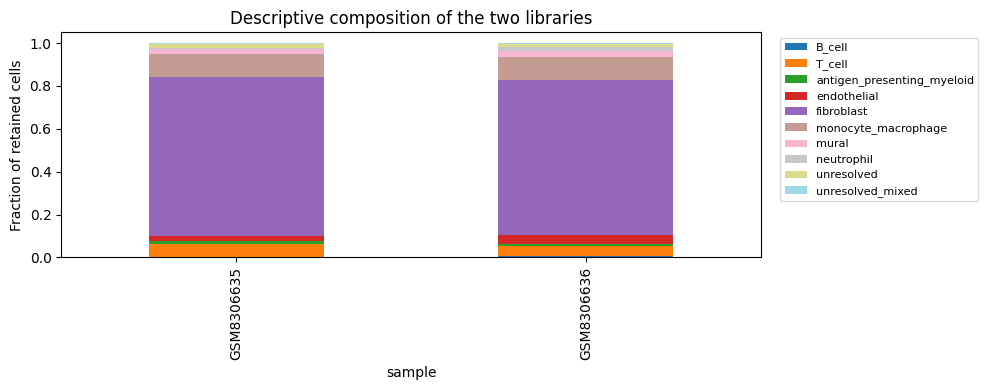

No composition significance test: one sequenced library per condition; no peptide exposure.


In [14]:
cluster_counts = read_tsv(RESULTS / "singlecell/cluster_sample_counts.tsv", index_col=0)
# Recompute cell counts from the current metadata and annotation table.
cells = read_tsv(RESULTS / "singlecell/cell_metadata.tsv.gz", index_col=0, dtype={"leiden": str})
labels = annotations.set_index("cluster").provisional_cell_type
assert set(cells.leiden) == set(labels.index)
cells["provisional_cell_type"] = cells.leiden.map(labels)
celltype_counts = pd.crosstab(cells.provisional_cell_type, cells["sample"])
display(celltype_counts)
fractions = celltype_counts.div(celltype_counts.sum(axis=0), axis=1).T
ax = fractions.plot.bar(stacked=True, figsize=(10, 4), colormap="tab20")
ax.set(ylabel="Fraction of retained cells", title="Descriptive composition of the two libraries")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
print("No composition significance test: one sequenced library per condition; no peptide exposure.")

In [15]:
markers = read_tsv(RESULTS / "singlecell/cluster_markers_descriptive.tsv.gz", dtype={"group": str})
CLUSTER = "13"
assert CLUSTER in set(markers.group)
display(markers.loc[markers.group.eq(CLUSTER),
                    ["group", "names", "ensembl_id", "scores", "logfoldchanges", "pct_nz_group"]].head(20))
print("Cluster-marker statistics describe cells in this dataset; they are not peptide treatment effects.")

,group,names,ensembl_id,scores,logfoldchanges,pct_nz_group
235729,13,Lyz2,ENSRNOG00000005825,71.785934,7.749408,0.985437
235730,13,Bcl2a1,ENSRNOG00000047606,69.325710,6.762259,0.971845
235731,13,Fcgr2a,ENSRNOG00000046663,66.730250,6.439123,0.924272
235732,13,Fcer1g,ENSRNOG00000024159,66.315480,6.044187,0.929126
235733,13,RGD1559482,ENSRNOG00000048771,66.048670,6.696714,0.909223
235734,13,Alcam,ENSRNOG00000001989,66.003525,6.475405,0.922330
235735,13,Tyrobp,ENSRNOG00000020845,64.765280,5.654691,0.920874
235736,13,Cd14,ENSRNOG00000017819,64.762340,6.453266,0.901942
235737,13,Cxcl2,ENSRNOG00000002792,64.750450,7.351666,0.922330
235738,13,Ctsz,ENSRNOG00000050697,63.959020,6.006527,0.894660


Cluster-marker statistics describe cells in this dataset; they are not peptide treatment effects.


## Objective 2 — species-specific Reactome pathway associations

The pathway script uses native Ensembl mappings for rat and human separately. It removes version suffixes and deduplicates stable gene IDs, including primary/`_PAR_Y` mappings. Rat pathway annotations include electronically inferred orthologous pathways.

Each list uses a one-sided hypergeometric test, with BH correction across **all** size-eligible pathways, including zero overlaps. Pathway sizes are 5–500 genes after intersecting the background.

| Analysis | Foreground | Background | Interpretation |
| --- | --- | --- | --- |
| Rat 2019 | S5 or S6, intersected with S2 | Annotated genes in S2 | Conditional within the disease signature; not whole-transcriptome enrichment |
| Human bulk | FDR <0.05, up/down separately, primary model | Genes eligible for DESeq2 adjusted p values | Expression/pathway association within each contrast |
| Rat single-cell | Top 50 positive cluster markers; log2FC >0.5, ≥25% detection | Retained expressed rat genes | Descriptive cluster biology |

Enrichment does not establish pathway activation, inhibition, peptide binding, or causality. No sensitivity-model pathway analysis is claimed.

In [16]:
if RUN_ANALYSIS:
    run_stage([PYTHON, str(PROJECT / "scripts/pathways.py")])
else:
    print("Using saved Reactome enrichment outputs.")

mapping_audit = read_tsv(RESULTS / "pathways/mapping_audit.tsv")
display(mapping_audit)
display(pd.Series(json.loads((RESULTS / "pathways/methods.json").read_text()), name="method"))

Using saved Reactome enrichment outputs.


,analysis,input_query,input_background,annotated_background,annotated_query_in_background,query_outside_background,query_missing_annotation,pathways_tested,significant_FDR_005
0,rat_day3_conditional,258,617,354,139,4,115,63,0
1,rat_day5_conditional,107,617,354,62,1,44,63,0
2,LPS_10_vs_0_up,279,13637,7754,187,0,92,1426,3
3,LPS_10_vs_0_down,315,13637,7754,219,0,96,1426,13
4,LPS_1_vs_0_up,0,17772,8729,0,0,0,1502,0
5,LPS_1_vs_0_down,1,17772,8729,0,0,1,1502,0
6,LPS_3_vs_0_up,2,17772,8729,1,0,1,1502,0
7,LPS_3_vs_0_down,3,17772,8729,2,0,1,1502,0
8,basal_10_vs_0_up,414,13982,7840,328,0,86,1435,25
9,basal_10_vs_0_down,173,13982,7840,99,0,74,1435,23


database                                       Reactome direct Ensembl mappings; species-specific; no inferred human-symbol matching
release                                                                                                                           98
test                               one-sided hypergeometric over-representation, BH across every size-eligible pathway per gene list
pathway_size                                             5–500 genes after universe intersection; all overlaps including zero tested
rat_2019                             conditional enrichment among S2 disease genes only; S5/S6 genes outside S2 excluded and counted
human                                        up and down separately, padj<0.05; background = nonmissing DESeq2 padj in each contrast
singlecell                   top 50 cluster markers, log2FC>0.5, detected in >=25% of cluster; background = retained expressed genes
interpretation          Association with a gene set does not establis

In [17]:
for day in (3, 5):
    rat_pathways = read_tsv(RESULTS / f"pathways/rat_day{day}_conditional.tsv")
    print(f"Rat day {day}: {(rat_pathways.padj < 0.05).sum()} pathways at BH FDR <0.05")
    display(rat_pathways[["pathway", "overlap", "query_size", "pathway_size", "pvalue", "padj"]].head(5))
print("No significant conditional rat pathway enrichment; this does not reproduce or refute the paper's different enrichment analysis.")

Rat day 3: 0 pathways at BH FDR <0.05


,pathway,overlap,query_size,pathway_size,pvalue,padj
0,Regulation of TLR by endogenous ligand,4,139,5,0.080028,1.0
1,Collagen biosynthesis and modifying enzymes,5,139,7,0.087169,1.0
2,Neutrophil degranulation,23,139,48,0.123236,1.0
3,Ion transport by P-type ATPases,4,139,6,0.167222,1.0
4,Nuclear Receptor transcription pathway,4,139,6,0.167222,1.0


Rat day 5: 0 pathways at BH FDR <0.05


,pathway,overlap,query_size,pathway_size,pvalue,padj
0,Chemokine receptors bind chemokines,3,62,9,0.196409,1.0
1,Collagen degradation,2,62,5,0.211908,1.0
2,Activation of Matrix Metalloproteinases,2,62,5,0.211908,1.0
3,Amplification of signal from unattached kinetochores via a MAD2 inhibitory signal,2,62,6,0.283315,1.0
4,Separation of Sister Chromatids,2,62,6,0.283315,1.0


No significant conditional rat pathway enrichment; this does not reproduce or refute the paper's different enrichment analysis.


,pathway_id,pathway,overlap,query_size,pvalue,padj,genes
0,R-HSA-909733,Interferon alpha/beta signaling,26,328,1.758157e-20,2.522955e-17,ENSG00000055332;ENSG00000068079;ENSG00000089127;ENSG00000108424;ENSG00000111331;ENSG00000111335;ENSG000001...
1,R-HSA-9909505,Modulation of host responses by IFN-stimulated genes,11,328,3.263262e-11,2.341391e-08,ENSG00000107201;ENSG00000115267;ENSG00000121060;ENSG00000126709;ENSG00000137959;ENSG00000137965;ENSG000001...
2,R-HSA-877300,Interferon gamma signaling,15,328,4.269800e-07,2.042388e-04,ENSG00000065978;ENSG00000089127;ENSG00000111331;ENSG00000111335;ENSG00000115415;ENSG00000121060;ENSG000001...
3,R-HSA-168928,DDX58/IFIH1-mediated induction of interferon-alpha/beta,8,328,2.436517e-06,8.741003e-04,ENSG00000080824;ENSG00000107201;ENSG00000108771;ENSG00000115267;ENSG00000121060;ENSG00000138646;ENSG000001...
4,R-HSA-1236974,ER-Phagosome pathway,14,328,3.439549e-06,9.871505e-04,ENSG00000058262;ENSG00000099341;ENSG00000100911;ENSG00000101182;ENSG00000108671;ENSG00000130706;ENSG000001...
5,R-HSA-2980766,Nuclear Envelope Breakdown,5,328,6.276606e-06,1.501155e-03,ENSG00000113368;ENSG00000120802;ENSG00000160789;ENSG00000161904;ENSG00000175334
6,R-HSA-1169408,ISG15 antiviral mechanism,13,328,8.440973e-06,1.730400e-03,ENSG00000055332;ENSG00000107201;ENSG00000108424;ENSG00000115415;ENSG00000121060;ENSG00000125450;ENSG000001...
7,R-HSA-68949,Orc1 removal from chromatin,11,328,2.681717e-05,4.473910e-03,ENSG00000091651;ENSG00000099341;ENSG00000100297;ENSG00000101182;ENSG00000108671;ENSG00000112118;ENSG000001...
8,R-HSA-68867,Assembly of the pre-replicative complex,12,328,2.805937e-05,4.473910e-03,ENSG00000091651;ENSG00000099341;ENSG00000100297;ENSG00000101182;ENSG00000108106;ENSG00000108671;ENSG000001...
9,R-HSA-8983711,OAS antiviral response,5,328,4.664474e-05,6.693520e-03,ENSG00000089127;ENSG00000107201;ENSG00000111331;ENSG00000111335;ENSG00000135114


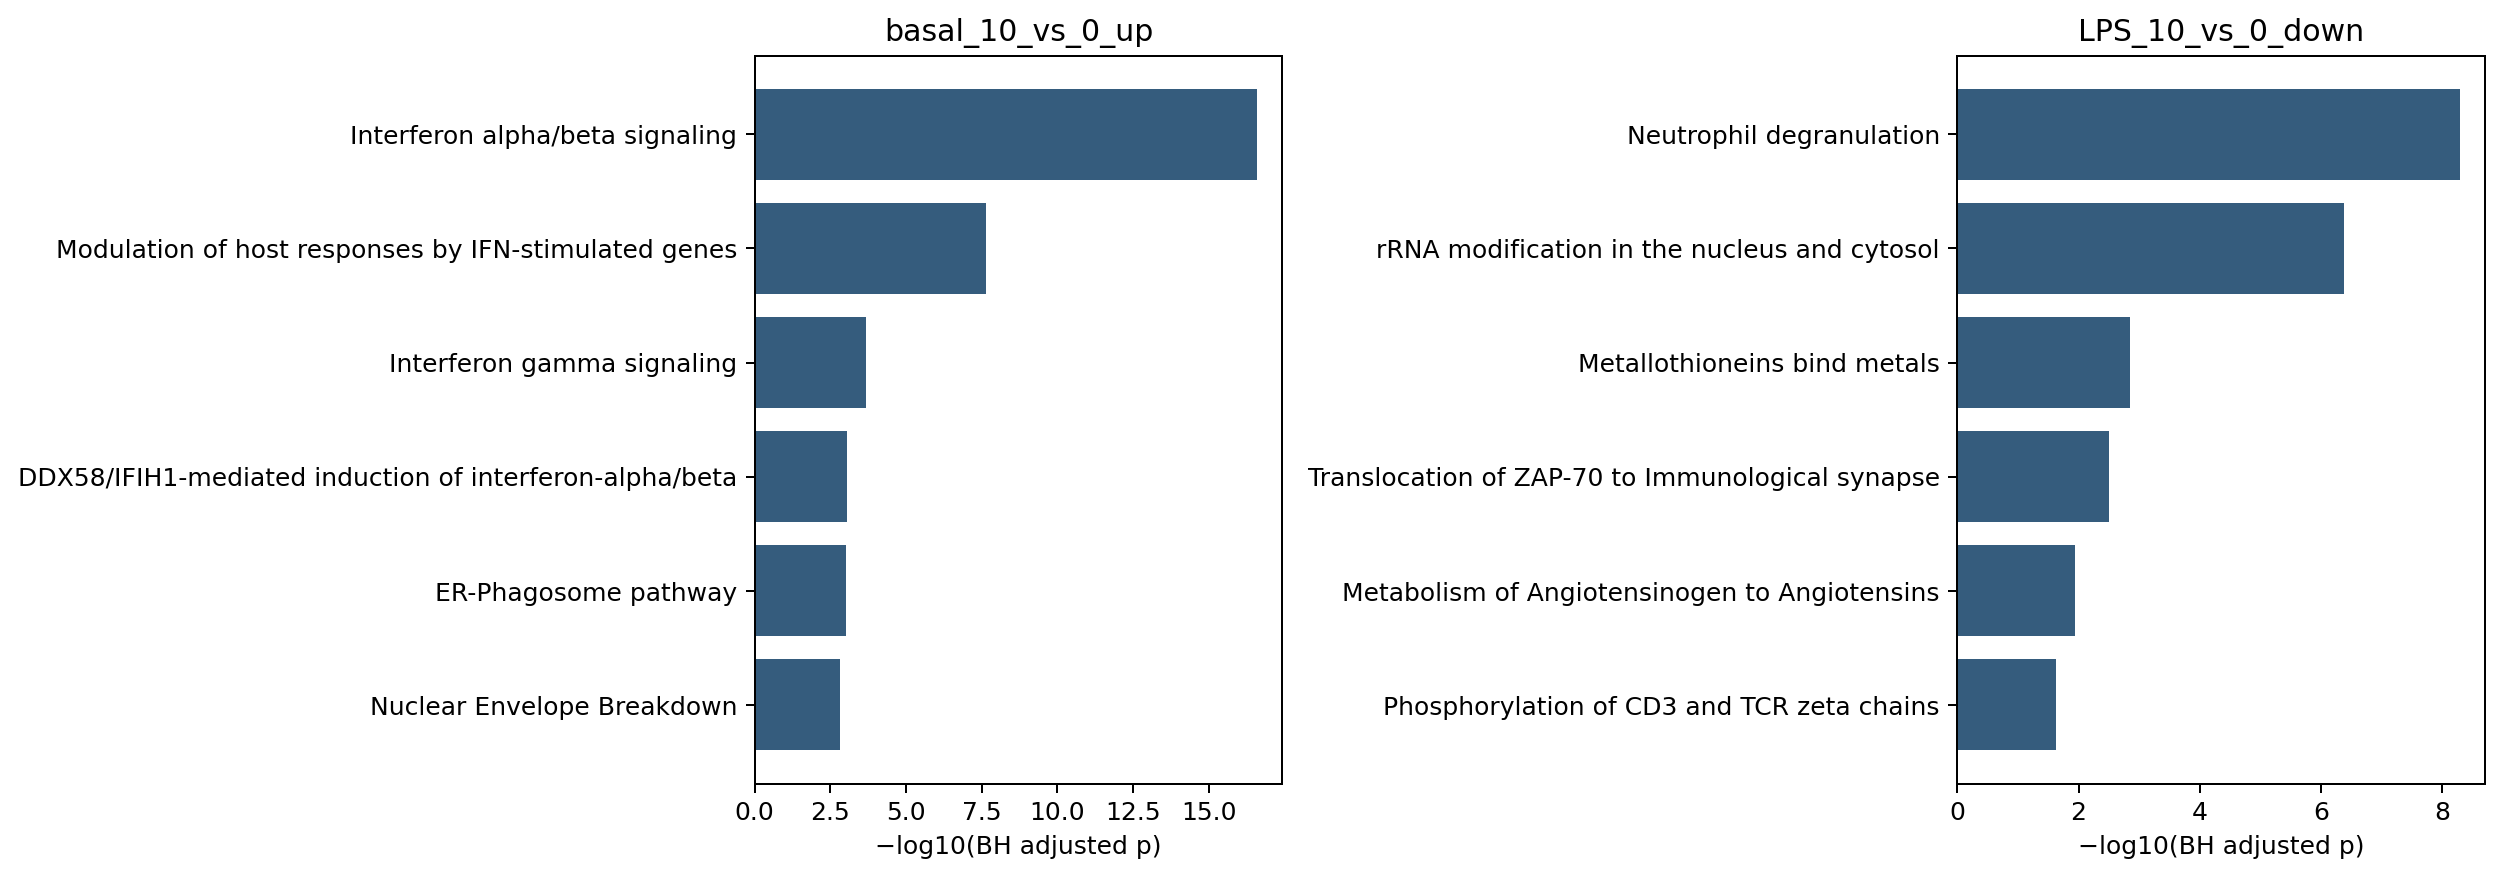

In [18]:
PATHWAY_ANALYSIS = "basal_10_vs_0_up"
assert PATHWAY_ANALYSIS in set(mapping_audit.analysis)
pathway_results = read_tsv(RESULTS / f"pathways/{PATHWAY_ANALYSIS}.tsv")
display(pathway_results.loc[pathway_results.padj < 0.05,
                            ["pathway_id", "pathway", "overlap", "query_size", "pvalue", "padj", "genes"]].head(15))
figure("pathways/human_10ug_enrichment.png")

### Interpretation of the observed primary-model results

At 10 µg/ml, the primary human bulk model identifies 587 significant features without LPS and 595 with LPS. Lower doses show fewer changes. The candidate-block model changes the totals, as shown above, so the precise counts are model-dependent.

Interferon alpha/beta signalling is the strongest association among upregulated genes without LPS. “Neutrophil degranulation” is the strongest association among downregulated genes in the LPS condition; a pathway name in THP-1 data does **not** establish neutrophil abundance.

The single-cell dataset describes possible cell populations and cluster-associated biology in rat synovium, but cannot establish an RTD-1- or MTD-specific cellular response. These resources do not supply a matched peptide comparison or direct peptide–protein interaction evidence.

## Validation and reproducibility record

Validation checks publisher/source integrity, sample-to-count alignment, exact preservation of rat source values, result/filter consistency, single-cell QC/count reconciliation, and species/background/BH consistency across 31 enrichment analyses. These are computational consistency checks; they do not constitute independent biological validation.

If a full recomputation was requested, the report is refreshed before validation. Otherwise the existing analyses are left unchanged apart from the validation record.

In [19]:
if RUN_ANALYSIS:
    run_stage([PYTHON, str(PROJECT / "scripts/report.py")])
if RUN_VALIDATION:
    run_stage([PYTHON, str(PROJECT / "scripts/validate.py")])
validation = json.loads((RESULTS / "validation.json").read_text())
assert validation["status"] == "passed"
display(pd.DataFrame({"passed_check": validation["checks"]}))

print("R environment used for the primary fit:")
print((RESULTS / "bulk/sessionInfo.txt").read_text())
print("Pinned Python dependencies: requirements.lock.txt")

{
  "status": "passed",
  "checks": [
    "All 13 primary downloads match recorded SHA256 checksums",
    "24 human samples match GEO accessions and exact rounded source counts; eight groups of three",
    "All six DESeq2 outputs cover exactly the independently verified 17,790-gene filter and reconcile with summaries",
    "Candidate-block sensitivity outputs reconcile across six contrasts, with unchanged source features",
    "Rat S2/S5/S6 values and IDs match workbook verbatim; discrepancy audit retained",
    "Single-cell dimensions, sample counts, QC thresholds, embedding, cluster counts and provisional annotations reconcile",
    "31 enrichment analyses satisfy species, universe, overlap and BH correction checks"
  ],
  "scope": "Specific Objectives 1 and 2 only"
}



,passed_check
0,All 13 primary downloads match recorded SHA256 checksums
1,24 human samples match GEO accessions and exact rounded source counts; eight groups of three
2,"All six DESeq2 outputs cover exactly the independently verified 17,790-gene filter and reconcile with summ..."
3,"Candidate-block sensitivity outputs reconcile across six contrasts, with unchanged source features"
4,Rat S2/S5/S6 values and IDs match workbook verbatim; discrepancy audit retained
5,"Single-cell dimensions, sample counts, QC thresholds, embedding, cluster counts and provisional annotation..."
6,"31 enrichment analyses satisfy species, universe, overlap and BH correction checks"


R environment used for the primary fit:
R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/blas/libblas.so.3.10.0 
LAPACK: /usr/lib/x86_64-linux-gnu/lapack/liblapack.so.3.10.0  LAPACK version 3.10.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Vancouver
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] DESeq2_1.52.0               SummarizedExperiment_1.36.0
 [3] Biobase_2.66.0              MatrixGenerics_1.18.1      
 [5] matrixStats_1.5.0           GenomicRanges_1.58.0       
 [7] GenomeI

## Deliverables, gaps, and primary sources

**Available:** dataset inventory and checksums; prepared rat tables and human counts/metadata; six primary DESeq2 contrasts and candidate-block sensitivity results; single-cell QC/clusters/provisional marker annotations; species-specific pathway analyses; plots and consistency checks.

**Still unavailable or unresolved:** rat sample-level counts in the 2019 supplement; a day-1 gene list sufficient to reconstruct the reported 340; explanation of supplementary-table discrepancies; verified experimental blocking; matched MTD expression data; sample-level cytokine/proteomics matrices in the inspected supplements; peptide-treated single-cell data. No author contact or figure digitization was performed.

The 2021 MTD12813 article states that underlying datasets are available from the corresponding author on reasonable request. This is an availability gap, not evidence that no such measurements exist.

- [2019 RTD-1 arthritis paper](https://doi.org/10.1152/physiolgenomics.00066.2019) and [supplement](https://doi.org/10.6084/m9.figshare.8855588).
- [Human RTD-1 bulk RNA-seq: GSE278567](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE278567).
- [Rat synovial single-cell data: GSE269120](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE269120) and [paper](https://doi.org/10.1186/s41232-024-00361-2).
- [2017 RTD-1 arthritis/protein study](https://doi.org/10.1371/journal.pone.0187868).
- [2021 MTD12813 study](https://doi.org/10.1038/s41598-021-02619-y).
- [DESeq2 documentation](https://bioconductor.org/packages/release/bioc/vignettes/DESeq2/inst/doc/DESeq2.html), [Scanpy workflow](https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html), [Reactome downloads](https://reactome.org/download-data).

Project references: [README and rerun instructions](README.md), [full analysis summary](results/analysis_summary.md), [dataset inventory](data/dataset_inventory.tsv), [validation record](results/validation.json).